**HW1: Thermal PDE solver implementation**

####*1. face conductivity 구현*
####*2. interior stencil 구현*
####*3. Dirichlet boundary condition 구현*



####**모두 구현한 뒤 run_demo()를 실행하고,max|Td - Tg| 값이 충분히 작은지 확인하시오.**

Td mean = 345.28973388671875
Tg mean = 345.29010009765625
max|Td-Tg| = 0.001312255859375


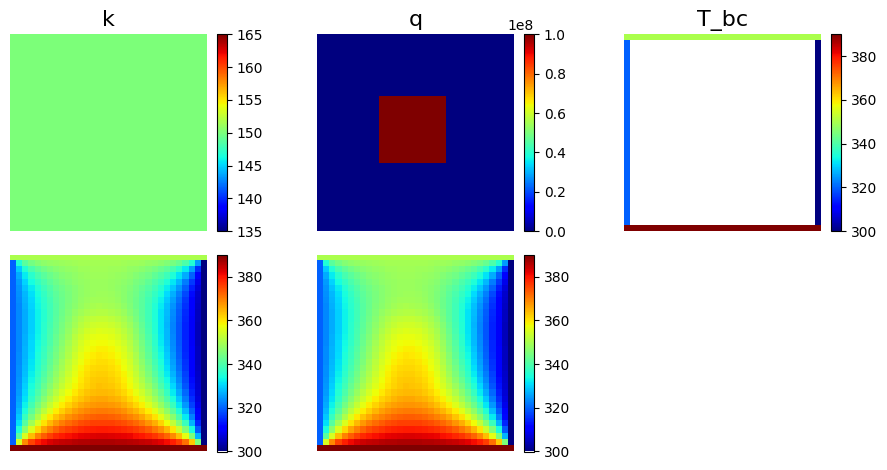

In [ ]:
import numpy as np
import torch
from typing import Optional, Dict, Any


def _harmonic_mean(a, b, eps=1e-12):
    return 2 * a * b / (a + b + eps)


class Heat2DSolver:
    def __init__(
        self,
        dx: float = 1.0,
        dy: float = 1.0,
        mode: str = "direct",
        reg: float = 1e-8,
        max_iter: int = 10000,
        tol: float = 1e-6,
        device: Optional[str] = None,
        dtype=torch.float32,
    ):
        self.dx = dx
        self.dy = dy
        self.mode = mode
        self.reg = reg
        self.max_iter = max_iter
        self.tol = tol
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.dtype = dtype

    def solve(
        self,
        k: torch.Tensor,
        q: torch.Tensor,
        T_bc: torch.Tensor,
        dirichlet_mask: torch.Tensor,
    ) -> torch.Tensor:
        k = k.to(device=self.device, dtype=self.dtype)
        q = q.to(device=self.device, dtype=self.dtype)
        T_bc = T_bc.to(device=self.device, dtype=self.dtype)
        dm = dirichlet_mask.to(self.device)

        if self.mode == "direct":
            return self._solve_direct(k, q, T_bc, dm)
        elif self.mode == "cg":
            return self._solve_cg(k, q, T_bc, dm)
        else:
            raise ValueError("mode must be 'direct' or 'cg'")

    def _solve_direct(self, k, q, T_bc, dm):
        B, H, W = k.shape
        N = H * W
        dx2 = self.dx ** 2
        dy2 = self.dy ** 2

        ke = torch.zeros_like(k)
        kw = torch.zeros_like(k)
        kn = torch.zeros_like(k)
        ks = torch.zeros_like(k)

        # TODO: compute face conductivities
        raise NotImplementedError("TODO: compute face conductivities ke, kw, kn, ks")
        ke[:,:,:-1] = _harmonic_mean(k[:,:,:-1], k[:,:,1:])
        kw[:,:,1:] = ke[:,:,:-1]
        kn
        ks

        A = torch.zeros(B, N, N, device=k.device, dtype=k.dtype)
        b = torch.zeros(B, N, device=k.device, dtype=k.dtype)

        for bidx in range(B):
            b[bidx] = -q[bidx].reshape(N)

            for i in range(H):
                for j in range(W):
                    idx = i * W + j

                    if dm[bidx, i, j]:
                        continue

                    # TODO: compute stencil coefficients and fill matrix row
                    raise NotImplementedError("TODO: fill interior stencil for direct solver")
                    ce = ke[bidx, i, j] / dx2
                    cw = kw[bidx, i, j / dx2
                    cn
                    cs

                    A[bidx, idx, idx] = -(ce + cw + cn + cs)
                    if j+1 < W: A[bidx, idx, idx+1] = ce
                    if j-1 >=0: A[bidx, idx, idx-1] = cw
                    if i+1 < H: A[bidx, idx, idx+W] = cn
                    if i-1 >=0: A[bidx, idx, idx-W] = cs

            flat_Tbc = T_bc[bidx].reshape(N)
            for idx in (dm[bidx].flatten() == True).nonzero(as_tuple=False).view(-1):
                # TODO: impose Dirichlet boundary condition row
                raise NotImplementedError("TODO: impose Dirichlet boundary condition")



        if self.reg > 0:
            eye = torch.eye(N, device=k.device, dtype=k.dtype).unsqueeze(0)
            interior = (~dm).reshape(B, N)
            A = A + eye * (self.reg * interior.unsqueeze(-1).to(k.dtype))

        T = torch.linalg.solve(A, b)
        return T.view(B, H, W)

    def _solve_cg(self, k, q, T_bc, dm):
        B, H, W = k.shape
        dx2 = self.dx ** 2
        dy2 = self.dy ** 2

        ke = torch.zeros_like(k)
        kw = torch.zeros_like(k)
        kn = torch.zeros_like(k)
        ks = torch.zeros_like(k)

        raise NotImplementedError("TODO: compute face conductivities ke, kw, kn, ks")

        def A_times(X):
            lap = (
                (ke * torch.roll(X, -1, 2) + kw * torch.roll(X, 1, 2)) / dx2
                + (kn * torch.roll(X, 1, 1) + ks * torch.roll(X, -1, 1)) / dy2
                - ((ke + kw) / dx2 + (kn + ks) / dy2) * X
            )

            lap[dm] = X[dm]
            return lap

        X = T_bc.clone()
        b = -q.clone()
        b[dm] = T_bc[dm]

        r = b - A_times(X)
        p = r.clone()
        rs = (r * r).flatten(1).sum(1, keepdim=True)

        for _ in range(self.max_iter):
            Ap = A_times(p)
            alpha = rs / (p * Ap).flatten(1).sum(1, keepdim=True)
            X = X + alpha.view(B, 1, 1) * p
            r = r - alpha.view(B, 1, 1) * Ap
            rs_new = (r * r).flatten(1).sum(1, keepdim=True)

            if (rs_new.sqrt() < self.tol).all():
                break

            p = r + (rs_new / rs).view(B, 1, 1) * p
            rs = rs_new

        return X


def solve_pde(problem: Dict[str, Any]):
    required_keys = ["k", "q", "T_bc", "dirichlet_mask", "dx", "dy", "reg"]
    for key in required_keys:
        if key not in problem:
            raise KeyError(f"Problem missing key: {key}")

    solver = Heat2DSolver(
        dx=problem["dx"],
        dy=problem["dy"],
        reg=problem["reg"],
        device=problem.get("device", None),
        dtype=problem.get("dtype", torch.float32),
        mode=problem.get("mode", "direct"),
    )

    return solver.solve(
        k=problem["k"],
        q=problem["q"],
        T_bc=problem["T_bc"],
        dirichlet_mask=problem["dirichlet_mask"],
    )


def plot_data(
    named_array_grid,
    origin="upper",
    save_path=None,
    same_clim_row=False,
    cmap="jet",
    titles_top_only=True,
    title_size=16,
    fig_scale=1.2,
    cbar_ticks=True,
):
    import matplotlib.pyplot as plt

    rows = len(named_array_grid)
    cols = max(len(row) for row in named_array_grid)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(2.6 * cols * fig_scale, 2.0 * rows * fig_scale),
    )

    if rows == 1:
        axes = np.expand_dims(axes, 0)
    if cols == 1:
        axes = np.expand_dims(axes, 1)
    axes = np.array(axes)

    vlims_row = [None] * rows
    if same_clim_row:
        for i in range(rows):
            vmins, vmaxs = [], []
            for item in named_array_grid[i]:
                if not item or item[1] is None or item[0] == "":
                    continue
                a = item[1].cpu().numpy() if hasattr(item[1], "cpu") else np.array(item[1])
                a = a[np.isfinite(a)]
                if a.size:
                    vmins.append(np.min(a))
                    vmaxs.append(np.max(a))
            if vmins:
                vlims_row[i] = (float(min(vmins)), float(max(vmaxs)))

    for i in range(rows):
        for j in range(cols):
            ax = axes[i, j]
            try:
                item = named_array_grid[i][j]
                if not item or item[1] is None or item[0] == "":
                    ax.axis("off")
                    continue

                name, arr = item
                if hasattr(arr, "cpu"):
                    arr = arr.cpu()
                arr = np.array(arr)

                vmin = vmax = None
                if same_clim_row and vlims_row[i] is not None:
                    vmin, vmax = vlims_row[i]

                im = ax.imshow(arr, origin=origin, cmap=cmap, vmin=vmin, vmax=vmax)

                if (not titles_top_only) or (i == 0):
                    ax.set_title(name, fontsize=title_size)
                ax.axis("off")

                if not np.isnan(arr).all():
                    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
                    if not cbar_ticks:
                        cb.set_ticks([])
                        cb.ax.tick_params(length=0, labelsize=0)

            except Exception:
                ax.axis("off")

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()


def make_input(B=1, H=32, W=32):
    k = torch.ones(B, H, W) * 150.0
    q = torch.zeros(B, H, W)

    h0, h1 = H // 3, 2 * H // 3
    w0, w1 = W // 3, 2 * W // 3
    q[:, h0:h1, w0:w1] = 1e8

    T_bc = torch.zeros(B, H, W)
    T_bc[:, :, 0] = 320.0
    T_bc[:, :, -1] = 300.0
    T_bc[:, 0, :] = 350.0
    T_bc[:, -1, :] = 390.0

    dirichlet_mask = torch.ones((B, H, W), dtype=torch.bool)
    dirichlet_mask[:, 1:-1, 1:-1] = False

    return k, q, T_bc, dirichlet_mask


def run_demo():
    dx = dy = 1e-3
    inputs = make_input()

    Td = Heat2DSolver(dx=dx, dy=dy, mode="direct").solve(*inputs)
    Tg = Heat2DSolver(dx=dx, dy=dy, mode="cg", max_iter=1000, tol=1e-8).solve(*inputs)

    print("Td mean =", Td.mean().item())
    print("Tg mean =", Tg.mean().item())
    print("max|Td-Tg| =", (Td - Tg).abs().max().item())

    k, q, T_bc, dirichlet_mask = inputs
    i = 0

    plot_data([
        [
            ("k", k[i]),
            ("q", q[i]),
            ("T_bc", np.where(dirichlet_mask[i].cpu().numpy(), T_bc[i].cpu().numpy(), np.nan)),
        ],
        [
            ("Td", Td[i]),
            ("Tcg", Tg[i]),
            None,
        ]
    ])


if __name__ == "__main__":
    run_demo()